In [41]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

In [42]:
# load dataset with adaptive path (local vs kaggle)
local_path = Path('data/Speed_Dating_Data.csv')
DATA_PATH = local_path if local_path.exists() else '/kaggle/input/datasets/annavictoria/speed-dating-experiment/Speed Dating Data.csv'

df = pd.read_csv(DATA_PATH, encoding='ISO-8859-1')
print(f"total observations (dates): {len(df)}")
print(f"unique participants: {df['iid'].nunique()}\n")

data_quality = pd.DataFrame({
    'type': df.dtypes,
    'missing': df.isna().sum(),
    'missing_share_%': (df.isna().mean() * 100).round(2)
})
print("--- data quality overview (top 5 missing) ---")
print(data_quality.sort_values('missing_share_%', ascending=False).head(5), "\n")

total observations (dates): 8378
unique participants: 551

--- data quality overview (top 5 missing) ---
             type  missing  missing_share_%
num_in_3  float64     7710            92.03
numdat_3  float64     6882            82.14
expnum    float64     6578            78.52
sinc7_2   float64     6423            76.67
amb7_2    float64     6423            76.67 



In [43]:
# feature selection
interaction_cols = ['wave', 'iid', 'pid', 'gender', 'round', 'order', 'dec', 'dec_o', 'match']
participant_profile = ['age', 'race', 'imprace', 'imprelig', 'goal', 'date', 'go_out']
partner_profile = ['age_o', 'race_o', 'samerace', 'int_corr']
ratings_given = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar', 'like', 'prob']
ratings_received = ['attr_o', 'sinc_o', 'intel_o', 'fun_o', 'amb_o', 'shar_o', 'like_o', 'prob_o']
interests = [
    'sports', 'tvsports', 'exercise', 'dining', 'museums', 'art', 'hiking', 
    'gaming', 'clubbing', 'reading', 'tv', 'theater', 'movies', 'concerts', 
    'music', 'shopping', 'yoga'
]

core_cols = interaction_cols + participant_profile + partner_profile + ratings_given + ratings_received + interests
clean_df = df[core_cols].copy()
clean_df = clean_df.dropna(subset=['pid', 'dec', 'dec_o', 'match'])
clean_df['pid'] = clean_df['pid'].astype(int)

# enrich partner features
profiles = df[['iid', 'goal'] + interests].drop_duplicates('iid').set_index('iid')
clean_df = clean_df.join(profiles, on='pid', rsuffix='_o')

# feature engineering: goal match (nan if either is missing)
clean_df['goal_match'] = np.where(
    clean_df['goal'].isna() | clean_df['goal_o'].isna(), 
    np.nan, 
    (clean_df['goal'] == clean_df['goal_o']).astype(float)
)

# feature engineering: interests cosine similarity (only for complete interest vectors to avoid nansum bias)
vec_i = clean_df[interests].values.astype(float)
vec_j = clean_df[[i + '_o' for i in interests]].values.astype(float)
num = np.sum(vec_i * vec_j, axis=1)
den = np.sqrt(np.sum(vec_i**2, axis=1)) * np.sqrt(np.sum(vec_j**2, axis=1))
clean_df['interest_cos'] = np.where(den > 0, num / den, np.nan)

# check for missing data bias using a specific subset
model_features = ['int_corr', 'age', 'age_o', 'samerace', 'goal_match', 'interest_cos']
clean_df_nona = clean_df.dropna(subset=['match', 'dec'] + model_features).copy()
dropped_df = clean_df[~clean_df.index.isin(clean_df_nona.index)]

print("--- missing data bias check ---")
print(f"kept rows: {len(clean_df_nona)} | dropped rows: {len(dropped_df)}")
print(f"match rate in kept: {clean_df_nona['match'].mean():.2%} | match rate in dropped: {dropped_df['match'].mean():.2%}")
if abs(clean_df_nona['match'].mean() - dropped_df['match'].mean()) > 0.05:
    print("warning: significant difference in match rates between kept and dropped data.\n")
else:
    print("ok: dropping nans does not heavily skew the baseline match rate.\n")

--- missing data bias check ---
kept rows: 8148 | dropped rows: 220
match rate in kept: 16.47% | match rate in dropped: 17.27%
ok: dropping nans does not heavily skew the baseline match rate.



--- h1: attention inequality evaluation ---

[Female]
  Observed Gini: 0.286 (95% CI: 0.262-0.309) | Null p95: 0.205
  Top-20% Share: 34.2% (95% CI: 32.7%-35.7%) | Null p95: 30.3%

[Male]
  Observed Gini: 0.351 (95% CI: 0.321-0.379) | Null p95: 0.257
  Top-20% Share: 38.3% (95% CI: 36.3%-40.1%) | Null p95: 33.3%


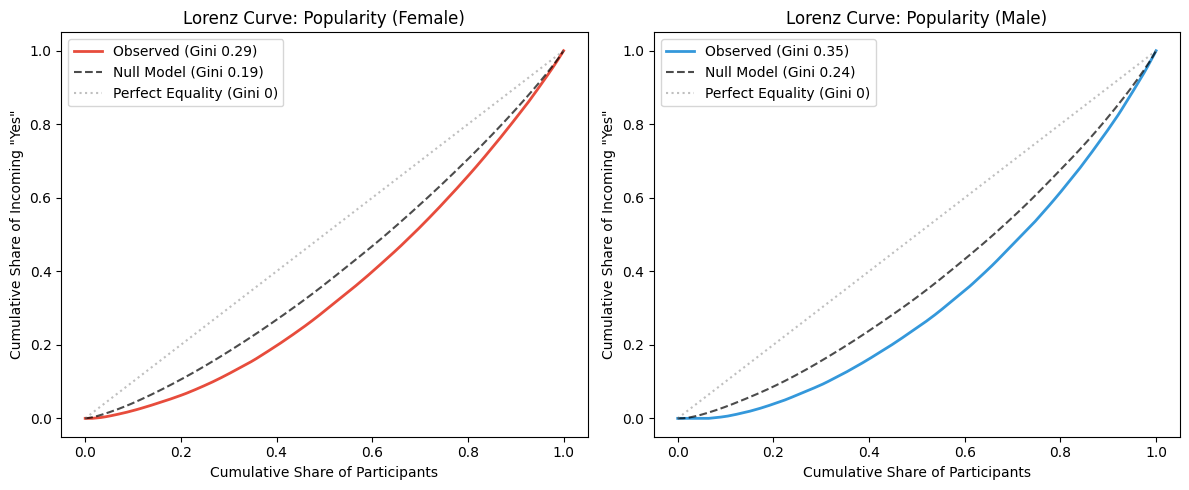

In [44]:
# h1: attention inequality (gini, top-20%, and simulated null curve)
rng = np.random.default_rng(42)

def calculate_gini(array):
    arr = np.array(array, dtype=np.float64) + 1e-9
    arr = np.sort(arr)
    n = arr.shape[0]
    index = np.arange(1, n + 1)
    return float(np.sum((2 * index - n - 1) * arr) / (n * np.sum(arr)))

def top_share(x, q=0.2):
    x = np.sort(np.asarray(x))[::-1]
    return float(x[:max(1, round(len(x) * q))].sum() / (x.sum() + 1e-9))

def bootstrap_metrics(data, n_iter=1000, ci=95):
    gini_sims, top_sims = [], []
    for _ in range(n_iter):
        sample = rng.choice(data, size=len(data), replace=True)
        gini_sims.append(calculate_gini(sample))
        top_sims.append(top_share(sample))
    g_low, g_high = np.percentile(gini_sims, [(100 - ci) / 2.0, 100 - (100 - ci) / 2.0])
    t_low, t_high = np.percentile(top_sims, [(100 - ci) / 2.0, 100 - (100 - ci) / 2.0])
    return g_low, g_high, t_low, t_high

user_metrics = clean_df.groupby(['iid', 'gender', 'wave']).agg(
    dates_count=('dec', 'count'), out_yes=('dec', 'sum'), in_yes=('dec_o', 'sum'), matches=('match', 'sum')
).reset_index()

user_metrics['selectivity'] = user_metrics['out_yes'] / user_metrics['dates_count']
user_metrics['popularity'] = user_metrics['in_yes'] / user_metrics['dates_count']

fig_lorenz, axes = plt.subplots(1, 2, figsize=(12, 5))
print("--- h1: attention inequality evaluation ---")

for i, (g_val, g_name) in enumerate(zip([0, 1], ['Female', 'Male'])):
    sub = user_metrics[user_metrics['gender'] == g_val].copy()
    pop_data = sub['popularity'].values
    
    # simulate wave-aware null distributions
    p_wave = sub.groupby('wave')['popularity'].transform('mean').values
    n_dates = sub['dates_count'].values
    
    sim_ginis, sim_tops, null_curves = [], [], []
    for _ in range(1000):
        sim_pop = rng.binomial(n_dates, p_wave) / n_dates
        sim_ginis.append(calculate_gini(sim_pop))
        sim_tops.append(top_share(sim_pop))
        sorted_sim = np.sort(sim_pop)
        null_curves.append(np.insert(np.cumsum(sorted_sim) / sorted_sim.sum(), 0, 0))
    
    obs_gini = calculate_gini(pop_data)
    obs_top20 = top_share(pop_data)
    g_low, g_high, t_low, t_high = bootstrap_metrics(pop_data)
    null_g_p95, null_t_p95 = np.percentile(sim_ginis, 95), np.percentile(sim_tops, 95)
    
    # plot observed lorenz
    sorted_pop = np.sort(pop_data)
    cum_pop = np.insert(np.cumsum(sorted_pop) / sorted_pop.sum(), 0, 0)
    percentiles = np.linspace(0, 1, len(cum_pop))
    axes[i].plot(percentiles, cum_pop, label=f'Observed (Gini {obs_gini:.2f})', color='#e74c3c' if g_val==0 else '#3498db', lw=2)
    
    # plot mean null curve
    mean_null_curve = np.mean(np.array(null_curves), axis=0)
    axes[i].plot(percentiles, mean_null_curve, 'k--', label=f'Null Model (Gini {np.mean(sim_ginis):.2f})', alpha=0.7)
    axes[i].plot([0, 1], [0, 1], color='gray', linestyle=':', label='Perfect Equality (Gini 0)', alpha=0.5)
    
    axes[i].set_title(f'Lorenz Curve: Popularity ({g_name})')
    axes[i].set_xlabel('Cumulative Share of Participants')
    axes[i].set_ylabel('Cumulative Share of Incoming "Yes"')
    axes[i].legend()
    
    print(f"\n[{g_name}]")
    print(f"  Observed Gini: {obs_gini:.3f} (95% CI: {g_low:.3f}-{g_high:.3f}) | Null p95: {null_g_p95:.3f}")
    print(f"  Top-20% Share: {obs_top20:.1%} (95% CI: {t_low:.1%}-{t_high:.1%}) | Null p95: {null_t_p95:.1%}")

plt.tight_layout()
os.makedirs('reports/figures', exist_ok=True)
plt.savefig('reports/figures/lorenz_curves.png', dpi=300)
plt.show()

In [45]:
# h2: selectivity precision (pooled conversion within gender quintiles)
user_metrics['match_conversion'] = np.where(
    user_metrics['out_yes'] > 0,
    user_metrics['matches'] / user_metrics['out_yes'],
    np.nan
)

# break ties randomly before ranking to avoid sorting by wave implicitly
user_metrics['selectivity_noisy'] = user_metrics['selectivity'] + rng.normal(0, 1e-9, size=len(user_metrics))
quintile_labels = ['Very Selective', 'Selective', 'Moderate', 'Generous', 'Spam-like']
user_metrics['selectivity_quintile'] = user_metrics.groupby('gender')['selectivity_noisy'].transform(
    lambda x: pd.qcut(x.rank(method='first'), q=5, labels=quintile_labels)
)

selectivity_analysis = user_metrics.groupby(['gender', 'selectivity_quintile'], observed=True).agg(
    users_cnt=('iid', 'count'),
    mean_yes_rate=('selectivity', 'mean'),
    sum_matches=('matches', 'sum'),
    sum_outgoing_yes=('out_yes', 'sum')
).reset_index()

selectivity_analysis['pooled_match_conversion'] = selectivity_analysis['sum_matches'] / selectivity_analysis['sum_outgoing_yes']
selectivity_analysis['gender'] = selectivity_analysis['gender'].map({0: 'Female', 1: 'Male'})

print("\n--- h2: selectivity precision ---")
print(selectivity_analysis[['gender', 'selectivity_quintile', 'mean_yes_rate', 'pooled_match_conversion']].round(3))

# h2: binomial glm check to ensure selectivity effect is not just confounding with popularity
print("\n--- h2: selectivity vs popularity (binomial glm confounding check) ---")
for g_val, g_name in [(0, 'Female'), (1, 'Male')]:
    u = user_metrics[(user_metrics['gender'] == g_val) & (user_metrics['out_yes'] > 0)].copy()
    X = sm.add_constant(u[['selectivity', 'popularity']])
    # successes (matches) and failures (yes decisions that did not match)
    y = np.column_stack([u['matches'], u['out_yes'] - u['matches']])
    fit = sm.GLM(y, X, family=sm.families.Binomial()).fit(cov_type='HC1')
    print(f"[{g_name}] coefficients: {fit.params.round(3).to_dict()}")
    print(f"[{g_name}] p-values:     {fit.pvalues.round(3).to_dict()}")


--- h2: selectivity precision ---
   gender selectivity_quintile  mean_yes_rate  pooled_match_conversion
0  Female       Very Selective          0.062                    0.559
1  Female            Selective          0.223                    0.578
2  Female             Moderate          0.363                    0.532
3  Female             Generous          0.498                    0.412
4  Female            Spam-like          0.722                    0.385
5    Male       Very Selective          0.139                    0.468
6    Male            Selective          0.327                    0.440
7    Male             Moderate          0.453                    0.413
8    Male             Generous          0.618                    0.333
9    Male            Spam-like          0.872                    0.262

--- h2: selectivity vs popularity (binomial glm confounding check) ---
[Female] coefficients: {'const': -2.488, 'selectivity': -0.113, 'popularity': 5.215}
[Female] p-values:     {'co

In [46]:
# h3: ranking evaluation, candidate stats computed in-fold (no label leakage)
base = clean_df[clean_df['gender'] == 1].copy() # one row per date: i = male viewer, j = female candidate
base['age_diff_signed'] = base['age'] - base['age_o']

pair_feats = ['int_corr', 'age_diff_signed', 'samerace', 'goal_match', 'interest_cos']
features = ['pop_j', 'sel_j'] + pair_feats
pair_df = base.dropna(subset=['match', 'dec'] + pair_feats).copy()

def cand_stats(src):
    # pop_j: share of viewers who said yes to j; sel_j: j's own yes-rate
    return src.groupby('pid').agg(pop_j=('dec', 'mean'), sel_j=('dec_o', 'mean'))

def add_stats_out_of_fold(train, n_inner=5):
    # a training row never sees its own label: its stats come from other viewers
    parts = []
    for itr, ite in GroupKFold(n_splits=n_inner).split(train, groups=train['iid']):
        s = cand_stats(base[base['iid'].isin(train.iloc[itr]['iid'])])
        parts.append(train.iloc[ite].join(s, on='pid'))
    return pd.concat(parts)

feature_sets = {
    'A_interest':  (features, 'dec'),                                  # viewer's own interest
    'B_mutual':    (features, 'match'),                                # mutual match, all features
    'B_cand_only': (['pop_j', 'sel_j'], 'match'),                      # no pair-level features
    'B_no_sel_j':  ([f for f in features if f != 'sel_j'], 'match'),   # without candidate's selectivity
}

records = []
print("\n--- h3: recommender ranking evaluation (ablation study out-of-fold) ---")

for tr, te in GroupKFold(n_splits=5).split(pair_df, groups=pair_df['iid']):
    train, test = pair_df.iloc[tr], pair_df.iloc[te].copy()
    test = test.join(cand_stats(base[base['iid'].isin(train['iid'])]), on='pid')
    train = add_stats_out_of_fold(train)
    
    for name, (feats, target) in feature_sets.items():
        m = HistGradientBoostingClassifier(max_depth=3, random_state=42).fit(train[feats], train[target])
        test[name] = m.predict_proba(test[feats])[:, 1]
        
    for uid, u in test.groupby('iid'):
        row = {'iid': uid, 'top3_random': u['match'].mean()}   # random pick = user's own match rate
        for name in feature_sets:
            row[f'auc_{name}'] = roc_auc_score(u['match'], u[name]) if u['match'].nunique() > 1 else np.nan
            row[f'top3_{name}'] = u.nlargest(3, name)['match'].mean() if len(u) >= 3 else np.nan
        records.append(row)

res = pd.DataFrame(records)

def lift(a, b, metric):
    d = (res[f'{metric}_{b}'] - res[f'{metric}_{a}']).dropna()
    return f"{d.mean():+.4f} ± {1.96 * stats.sem(d):.4f} (users = {len(d)})"

print(f"N dates = {len(pair_df)}, viewers = {pair_df['iid'].nunique()}")
print("\nmean per-user AUC (absolute levels):")
print(res.filter(like='auc_').mean().round(3))
print("\nmean top-3 match rate (absolute levels):")
print(res.filter(like='top3_').mean().round(3))

print("\nlifts (ablation & objective comparisons):")
for a, b in [('A_interest', 'B_mutual'), ('B_cand_only', 'B_mutual'), ('B_no_sel_j', 'B_mutual')]:
    print(f"{a} -> {b}:\n  AUC:  {lift(a, b, 'auc')}\n  top3: {lift(a, b, 'top3')}")
    
print("\nnote: +0.02 threshold rule applied only to pair-level lift (B_cand_only -> B_mutual). A_interest -> B_mutual is exploratory.")


--- h3: recommender ranking evaluation (ablation study out-of-fold) ---
N dates = 4074, viewers = 274

mean per-user AUC (absolute levels):
auc_A_interest     0.584
auc_B_mutual       0.641
auc_B_cand_only    0.651
auc_B_no_sel_j     0.574
dtype: float64

mean top-3 match rate (absolute levels):
top3_random         0.169
top3_A_interest     0.237
top3_B_mutual       0.255
top3_B_cand_only    0.259
top3_B_no_sel_j     0.206
dtype: float64

lifts (ablation & objective comparisons):
A_interest -> B_mutual:
  AUC:  +0.0577 ± 0.0391 (users = 225)
  top3: +0.0182 ± 0.0313 (users = 274)
B_cand_only -> B_mutual:
  AUC:  -0.0094 ± 0.0254 (users = 225)
  top3: -0.0036 ± 0.0223 (users = 274)
B_no_sel_j -> B_mutual:
  AUC:  +0.0670 ± 0.0310 (users = 225)
  top3: +0.0499 ± 0.0267 (users = 274)

note: +0.02 threshold rule applied only to pair-level lift (B_cand_only -> B_mutual). A_interest -> B_mutual is exploratory.



--- decision drivers (standardized logistic regression) ---
                   gender factor   coef  se_cluster  p_value  N_dates
1  Female evaluating Male   attr  0.817       0.099    0.000     3457
6  Female evaluating Male   shar  0.609       0.086    0.000     3457
4  Female evaluating Male    fun  0.566       0.090    0.000     3457
3  Female evaluating Male  intel  0.208       0.097    0.031     3457
2  Female evaluating Male   sinc -0.169       0.112    0.130     3457
5  Female evaluating Male    amb -0.320       0.091    0.000     3457
1  Male evaluating Female   attr  1.264       0.088    0.000     3574
6  Male evaluating Female   shar  0.566       0.085    0.000     3574
4  Male evaluating Female    fun  0.482       0.076    0.000     3574
3  Male evaluating Female  intel -0.055       0.080    0.489     3574
2  Male evaluating Female   sinc -0.256       0.086    0.003     3574
5  Male evaluating Female    amb -0.264       0.068    0.000     3574


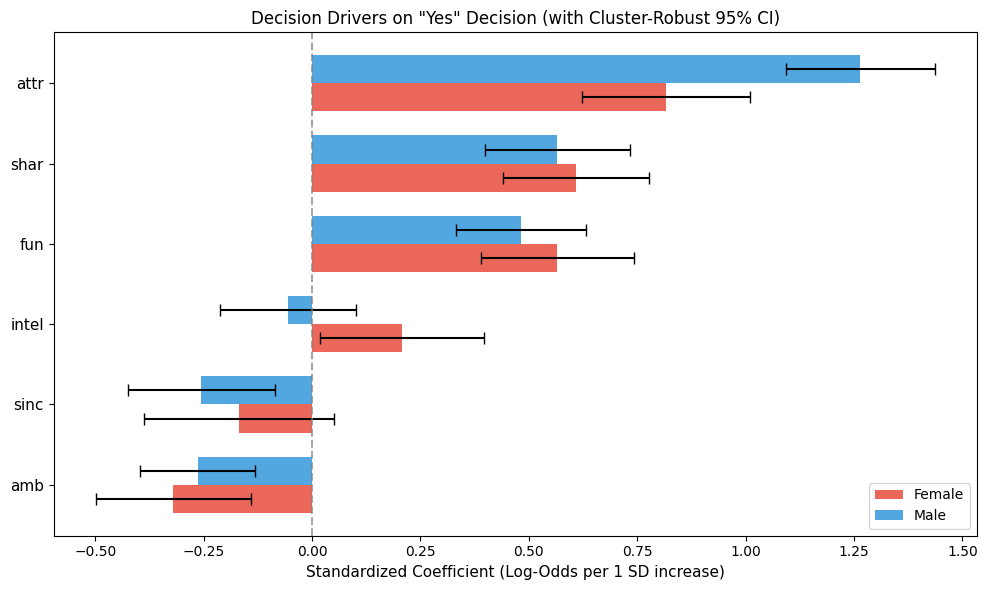


> CAVEAT: Trait ratings (`attr`, `fun`, `shar`) are recorded simultaneously with the decision and may reflect a halo effect rather than distinct causal drivers.


In [47]:
# decision drivers
ratings = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']

def run_driver_analysis(gender_val, gender_label):
    subset = clean_df[clean_df['gender'] == gender_val].dropna(subset=ratings + ['dec']).copy()
    
    for col in ratings:
        subset[col] = (subset[col] - subset[col].mean()) / subset[col].std()
        
    x = sm.add_constant(subset[ratings])
    y = subset['dec']
    model = sm.Logit(y, x).fit(cov_type='cluster', cov_kwds={'groups': subset['iid']}, disp=False)
    
    odds_ratios = pd.DataFrame({
        'factor': model.params.index,
        'coef': model.params.values,
        'p_value': model.pvalues.values,
        'se_cluster': model.bse.values
    }).query("factor != 'const'").sort_values(by='coef', ascending=False)
    
    odds_ratios['gender'] = gender_label
    # attaching sample size for output visibility
    odds_ratios['N_dates'] = len(subset) 
    return odds_ratios

drivers_summary = pd.concat([run_driver_analysis(0, 'Female evaluating Male'), run_driver_analysis(1, 'Male evaluating Female')])

print("\n--- decision drivers (standardized logistic regression) ---")
print(drivers_summary[['gender', 'factor', 'coef', 'se_cluster', 'p_value', 'N_dates']].round(3))

fig, ax = plt.subplots(figsize=(10, 6))
pivot_coef = drivers_summary.pivot(index='factor', columns='gender', values='coef')
pivot_se = drivers_summary.pivot(index='factor', columns='gender', values='se_cluster')

sort_order = pivot_coef['Male evaluating Female'].sort_values().index
pivot_coef, pivot_se = pivot_coef.loc[sort_order], pivot_se.loc[sort_order]

y_pos = np.arange(len(sort_order))
bar_width = 0.35

ax.barh(y_pos - bar_width/2, pivot_coef['Female evaluating Male'], bar_width, xerr=1.96 * pivot_se['Female evaluating Male'], label='Female', color='#e74c3c', alpha=0.85, capsize=4)
ax.barh(y_pos + bar_width/2, pivot_coef['Male evaluating Female'], bar_width, xerr=1.96 * pivot_se['Male evaluating Female'], label='Male', color='#3498db', alpha=0.85, capsize=4)

ax.set_yticks(y_pos)
ax.set_yticklabels(sort_order, fontsize=11)
ax.axvline(0, color='gray', linestyle='--', alpha=0.7)
ax.set_xlabel('Standardized Coefficient (Log-Odds per 1 SD increase)', fontsize=11)
ax.set_title('Decision Drivers on "Yes" Decision (with Cluster-Robust 95% CI)', fontsize=12)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('reports/figures/drivers_odds_ratio.png', dpi=300)
plt.show()

print("\n> CAVEAT: Trait ratings (`attr`, `fun`, `shar`) are recorded simultaneously with the decision and may reflect a halo effect rather than distinct causal drivers.")